####  books to scrap

In [1]:
import requests  # accees the data from website
from bs4 import BeautifulSoup # html la soup sarkh parse karun tyatle ingredients(tags,text,attributes) vegle kadhata yetat ani amt,rating,title milte
import pandas as pd # data dataframe mdhe thevto

In [2]:
url = "https://books.toscrape.com/catalogue/category/books_1/index.html"
response = requests.get(url)
soup = BeautifulSoup(response.text,'html.parser')  #creat object
#print(soup)
books=soup.find_all('article', class_='product_pod')
data=[]

for book in books:
    title = book.h3.a['title']
    price = book.find('p',class_='price_color').text[2:]
    rating = book.p['class'][1]
    data.append({'Title':title,'Price':price,'Rating':rating})

In [3]:
df = pd.DataFrame(data)
#df.head()
df.to_csv('First_Page.csv',index = False)


In [4]:
all_data = []
for page in range(1,51):
    url = f"https://books.toscrape.com/catalogue/category/books_1/page-{page}.html"
    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")
    books = soup.find_all('article',class_="product_pod")
    for book in books:
        title = book.h3.a['title']
        price = book.find("p", class_="price_color").text
        rating_class = book.find("p", class_="star-rating")["class"]
        availability = book.find("p", class_="instock availability").text.strip()
        all_data.append([title,price,rating_class[1], availability])
df = pd.DataFrame(all_data, columns= ["Title", "Price", "Rating", "Availability"])
df.to_csv("All_Data.csv", index = False)

In [5]:
df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [6]:
df.describe()

,Title,Price,Rating,Availability
count,1000,1000,1000,1000
unique,999,903,5,1
top,The Star-Touched Queen,Â£44.18,One,In stock
freq,2,3,226,1000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price         1000 non-null   object
 2   Rating        1000 non-null   object
 3   Availability  1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB


In [21]:
df.dtypes

Title            object
Price            object
Rating            int64
Availability     object
Price           float64
dtype: object

In [22]:
df.tail

<bound method NDFrame.tail of                                                  Title  Price  Rating  \
0                                 A Light in the Attic  51.77       3   
1                                   Tipping the Velvet  53.74       1   
2                                           Soumission  50.10       1   
3                                        Sharp Objects  47.82       4   
4                Sapiens: A Brief History of Humankind  54.23       5   
..                                                 ...    ...     ...   
995  Alice in Wonderland (Alice's Adventures in Won...  55.53       1   
996   Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)  57.06       4   
997  A Spy's Devotion (The Regency Spies of London #1)  16.97       5   
998                1st to Die (Women's Murder Club #1)  53.98       1   
999                 1,000 Places to See Before You Die  26.08       5   

    Availability  Price  
0       In stock  51.77  
1       In stock  53.74  
2       In stoc

In [23]:
df.shape

(1000, 5)

In [24]:
df['Price']

,Price,Price
0,51.77,51.77
1,53.74,53.74
2,50.10,50.10
3,47.82,47.82
4,54.23,54.23
...,...,...
995,55.53,55.53
996,57.06,57.06
997,16.97,16.97
998,53.98,53.98


In [33]:
# df['Price']=df['Price'].str.replace("Â£","",regex=False)
#df['price']=df['Price'].astype(float)

print(df.columns.tolist())
print(df.dtypes)

['Title', 'Price', 'Rating', 'Availability', 'price']
Title            object
Price            object
Rating            int64
Availability     object
price           float64
dtype: object


In [13]:
df.groupby('Rating')['price'].mean()


Rating
Five     35.374490
Four     36.093296
One      34.561195
Three    34.692020
Two      34.810918
Name: price, dtype: float64

In [14]:
df['price'].head()   # sorted and converted price column
print(df['Rating'].head())

0    Three
1      One
2      One
3     Four
4     Five
Name: Rating, dtype: object


In [15]:
rating_map = {
    'One': 1,
    'Two': 2,
    'Three': 3,
    'Four': 4,
    'Five': 5
}

df['Rating'] = df['Rating'].map(rating_map)

In [16]:
print(df['Rating'].head())
print(df['Rating'].dtype)

0    3
1    1
2    1
3    4
4    5
Name: Rating, dtype: int64
int64


In [17]:
df['Availability'].nunique 
print(df['Availability'].value_counts())

Availability
In stock    1000
Name: count, dtype: int64


In [35]:
print(df.columns.tolist())

['Title', 'Price', 'Rating', 'Availability', 'price']


In [36]:
# two times drop col available in float and text format deleteing text price col
df.drop(columns=['Price'], inplace=True)
df.rename(columns={'price':'Price'}, inplace=True)
print(df.columns.tolist())

['Title', 'Rating', 'Availability', 'Price']


In [37]:
print("___Data Quality Check___")

print(f"Total Rows: {len(df)}")
print(f"Missing Prices: {df['Price'].isnull().sum()}")
print(f"Missing Ratings: {df['Rating'].isnull().sum()}")

print(f"Negative Prices: {(df['Price'] <= 0).sum()}")
print(f"Negative Ratings: {(df['Rating'] <= 0).sum()}")

print(f"Duplicate Titles: {df.duplicated(subset=['Title']).sum()}")

___Data Quality Check___
Total Rows: 1000
Missing Prices: 0
Missing Ratings: 0
Negative Prices: 0
Negative Ratings: 0
Duplicate Titles: 1


In [38]:
df[df.duplicated(subset=['Title'],keep = False)]

,Title,Rating,Availability,Price
236,The Star-Touched Queen,5,In stock,46.02
358,The Star-Touched Queen,5,In stock,32.30


In [42]:
# Final Column Check
print(df.columns.tolist())

# CSV Export
df.to_csv(
    "books_cleaned.csv",
    index=False,
    encoding="utf-8"
)

print("CSV file exported successfully!")

['Title', 'Rating', 'Availability', 'Price']
CSV file exported successfully!


### Visualization

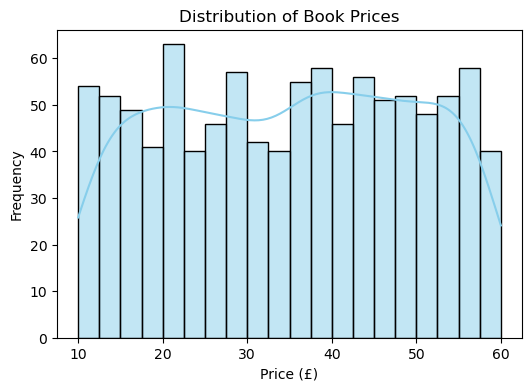

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.histplot(
    df['Price'],
    bins=20,
    kde=True,
    color='skyblue'
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.show()

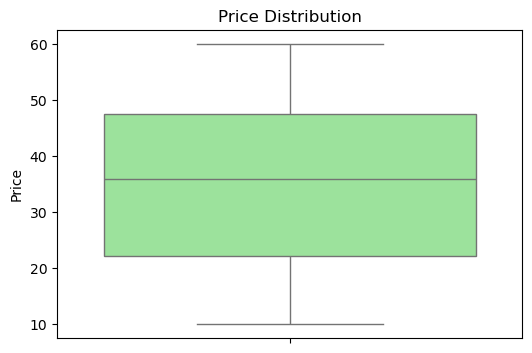

In [75]:
plt.figure(figsize=(6,4))

sns.boxplot(
    y=df['Price'],
    color='lightgreen'
)

plt.title("Price Distribution")

plt.show()


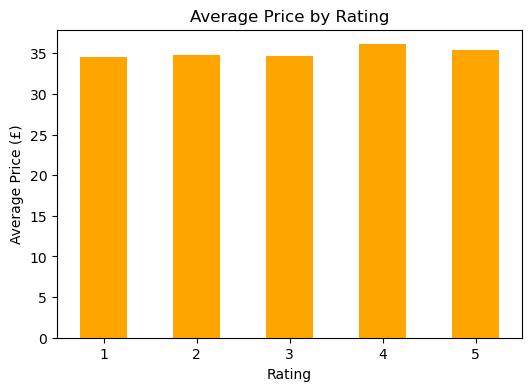

In [74]:
avg_price = df.groupby('Rating')['Price'].mean()

plt.figure(figsize=(6,4))

avg_price.plot(
    kind='bar',
    color='orange'
)

plt.title("Average Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price (£)")

plt.xticks(rotation=0)

plt.show()

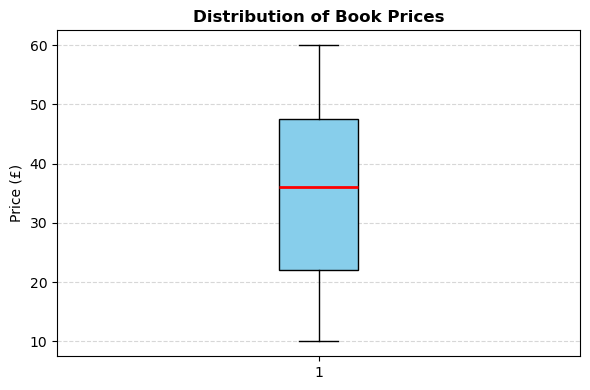

In [73]:
#Q create a boxplot and bar plot for rating column
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.boxplot(
    df['Price'],
    patch_artist=True,
    boxprops=dict(facecolor='skyblue'),
    medianprops=dict(color='red', linewidth=2)
)

plt.title("Distribution of Book Prices", fontweight='bold')
plt.ylabel("Price (£)")

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [60]:
## average book price
avg_Price = df['Price'].mean()
print(f"Average Book Price is: Rs. {avg_Price:.2f}")

Average Book Price is: Rs. 35.07


In [62]:
# cheapest vs most expensive Books
cheapest_book = df.loc[df['Price'].idxmin()]
expensive_book=df.loc[df['Price'].idxmax()]

print("cheapest_book:")
print(cheapest_book[['Title','Price']])
print("-------------------------------")
print("expensive_book:")
print(expensive_book[['Title','Price']])

cheapest_book:
Title    An Abundance of Katherines
Price                          10.0
Name: 638, dtype: object
-------------------------------
expensive_book:
Title    The Perfect Play (Play by Play #1)
Price                                 59.99
Name: 648, dtype: object


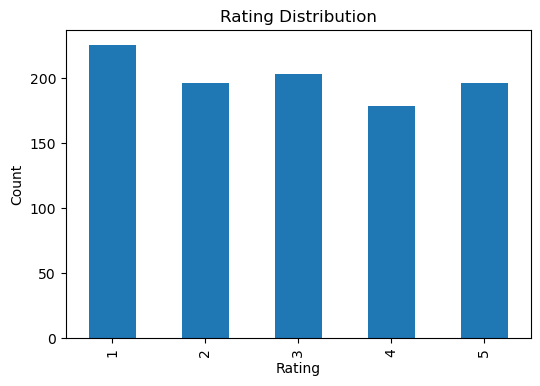

In [72]:
# visualize these result
plt.figure(figsize=(6,4))
df['Rating'].value_counts().sort_index().plot(kind='bar')
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

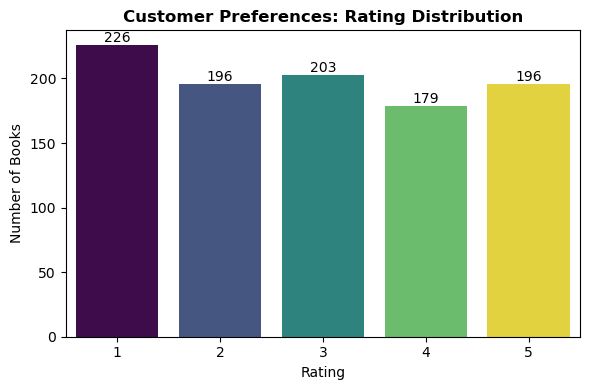

In [71]:
# create visualisation for price vs rating
df.columns
plt.figure(figsize=(6,4))

ax = sns.countplot(
    x='Rating',
    data=df,
    hue='Rating',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Customer Preferences: Rating Distribution", fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.show()

### conclusion 
